In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
pistack_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import grouped_boxplot_ax, box_plot_data
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import plot

os.chdir(pistack_dir)
df = pd.read_csv('hydrophobic_EDA.csv', index_col=0)
# df = raw_df.query('TOTAL < 0')
df.shape

(4971, 37)

In [3]:
print(len(df.query('TOTAL > 0'))) 
print(len(df.query('TOTAL < 0')))

159
4812


In [4]:
plot?

Signature:
plot(
    type,
    args,
    dfs,
    ax,
    cmap_range=[-100, 0.0],
    median=False,
    ratio1=False,
    ratio2=False,
    plot=False,
    kde_norm=False,
)
Docstring:
General Plot Function

Parameters
----------
type: {'ternary', 'bar', 'dist', 'box'}
    Plot types
args: list
    List of arguments for each plot type:
    - 'ternary': (label, index, type, cmap_range)
        - label: str
            type of atom/interaction
        - index: str
            index for ternary plot
        - type: str
            type of ternary plot ('frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct')
    - 'bar': (labels, items)
        - label: list(str)
            type of atom/interaction
        - items: list(str)
            EDA energy components 
    - 'dist': (column, labels, item, palette)
        - column: str
            column of dataframe
        - label: list(str)
            type of atom/interaction
        - item: list(str)
            EDA energy components
        - palette:

# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_1214/3785202499.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


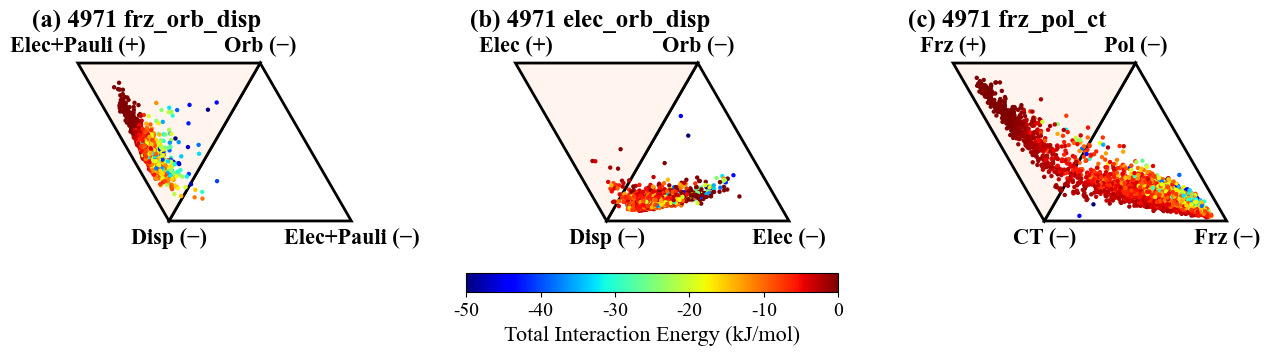

In [5]:
cmap_range = [-50, 0]
type0 = 'frz_orb_disp'
type1 = 'elec_orb_disp'
type2 = 'frz_pol_ct'
labels = [type0, type1, type2]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type0), df, axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type1), df, axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type2), df, axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary_frz_orb_disp.png')

# Energy Bar Plots

## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: list(map(len, dfs))
len: list(map(len, dfs))
len: list(map(len, dfs))
len: list(map(len, dfs))


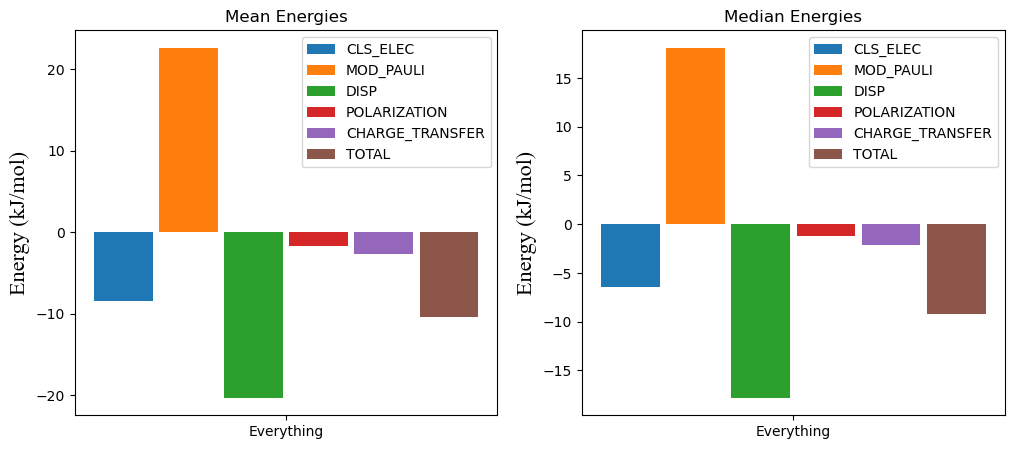

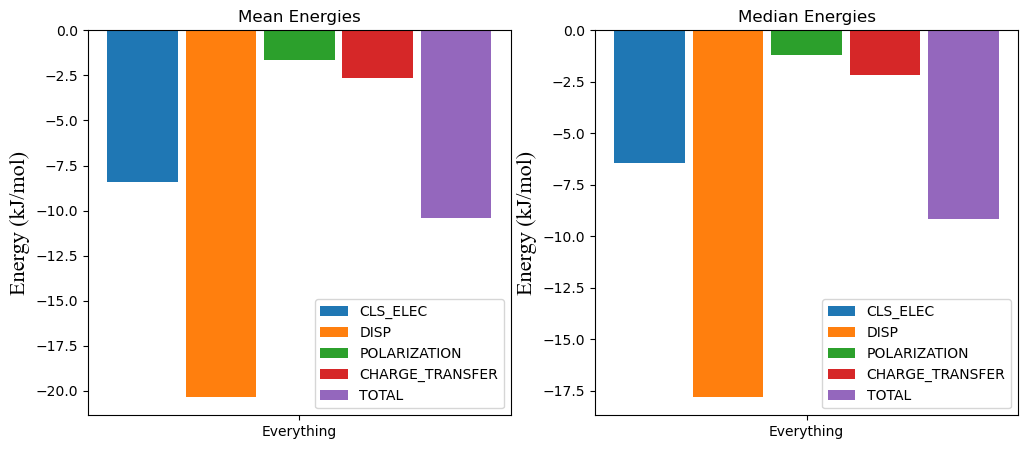

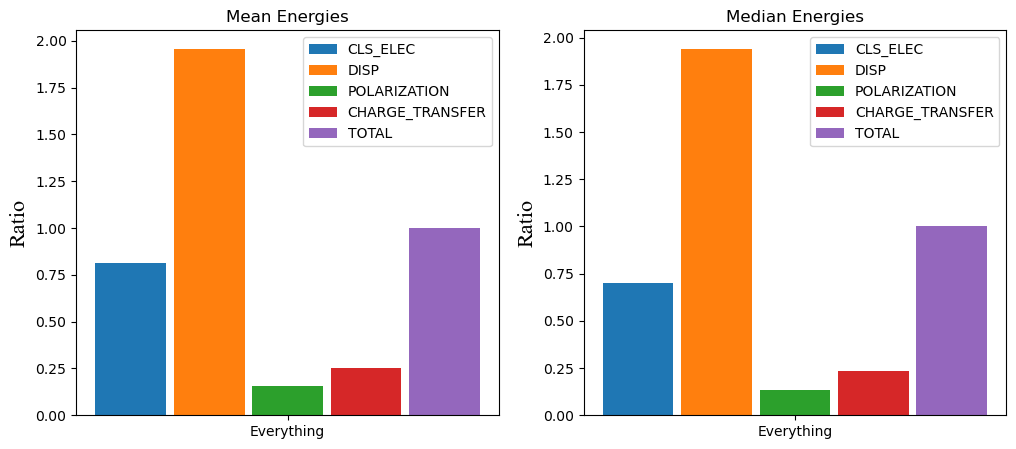

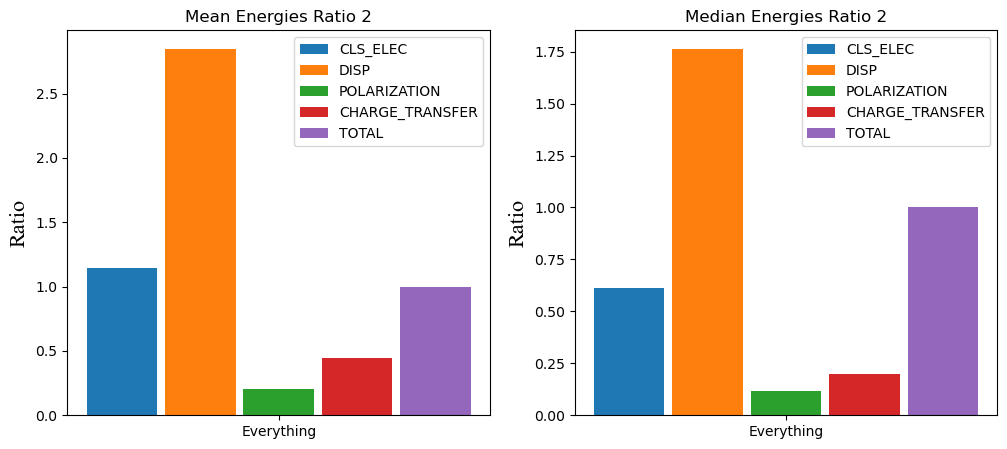

In [8]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot('bar', (['Everything'], items), [df], axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (['Everything'], items), [df], axes[1], median=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/hydrophobic.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot('bar', (['Everything'], items), [df], axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (['Everything'], items), [df], axes[1], median=True)
axes[1].set_title('Median Energies')
# plt.savefig('Visualizations/bar_Energy_pauli+disp_T-P.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot('bar', (['Everything'], items), [df], axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (['Everything'], items), [df], axes[1], ratio1=True, median=True)
axes[1].set_title('Median Energies')
# plt.savefig('Visualizations/bar_Energy_pauli+disp_T-P.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot('bar', (['Everything'], items), [df], axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio 2')
plot('bar', (['Everything'], items), [df], axes[1], ratio2=True, median=True)
axes[1].set_title('Median Energies Ratio 2')
plt.savefig('Visualizations/hydrophobic_ratio2.png')